John S. Anvik, 2025  
University of Lethbridge Student ID: 001224816

Import Packages

In [1]:
# install.packages("tidymodels")
# install.packages('rlang')
# install.packages("kknn")
library(tidyverse)
library(tidymodels)

# set random seed
set.seed(42)


Warning message:
"package 'tidyverse' was built under R version 4.4.3"
Warning message:
"package 'ggplot2' was built under R version 4.4.3"
Warning message:
"package 'tibble' was built under R version 4.4.3"
Warning message:
"package 'tidyr' was built under R version 4.4.3"
Warning message:
"package 'readr' was built under R version 4.4.3"
Warning message:
"package 'dplyr' was built under R version 4.4.3"
Warning message:
"package 'forcats' was built under R version 4.4.3"
Warning message:
"package 'lubridate' was built under R version 4.4.3"
── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package 

Load data

In [2]:
data <- read_csv("../data/matching_opportunities.csv") %>%
    drop_na() # drop any row containing at least one NA value

Rows: 245 Columns: 20
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl  (19): D_M1_M2, D_M1_M3, D_M1_M4, D_M1_M5, D_M1_M6, UST, M2_last_UST, M3...
dttm  (1): DateTime

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [3]:
# Model Inputs
model_inputs <- c(
        "UST", "does_it_match",
        "D_M1_M2", "D_M1_M3", "D_M1_M4", "D_M1_M5", "D_M1_M6",
        # TODO: Add M1 last UST, but shift it 1 back (not M1's current song, but M1's previous song)
        "M2_last_UST", "M3_last_UST", "M4_last_UST", "M5_last_UST", "M6_last_UST",
        # "time_M1_last_song", "time_M2_last_song", "time_M3_last_song", "time_M4_last_song", "time_M5_last_song", "time_M6_last_song",
    	"time_since_M2_last_song", "time_since_M3_last_song", "time_since_M4_last_song", "time_since_M5_last_song", "time_since_M6_last_song", # did not include time since M1 last song because it is always 0
        "time_rel_sunrise"
    )

In [4]:
# Set data types and select input columns
data <- data %>% 
    mutate(across(contains("UST"), ~ as.factor(.x)), 
        does_it_match = as.factor(does_it_match),
        number_of_matches = as.integer(number_of_matches)) %>%
    select(model_inputs)

Warning message:
"Using an external vector in selections was deprecated in tidyselect 1.1.0.
ℹ Please use `all_of()` or `any_of()` instead.
  # Was:
  data %>% select(model_inputs)

  # Now:
  data %>% select(all_of(model_inputs))

See <https://tidyselect.r-lib.org/reference/faq-external-vector.html>."


In [5]:
glimpse(data)

Rows: 214
Columns: 18
$ UST                     <fct> 3, 29, 10, 8, 3, 21, 5, 9, 29, 17, 29, 9, 21, …
$ does_it_match           <fct> 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0…
$ D_M1_M2                 <dbl> 94.0368, 94.0368, 94.0368, 94.0368, 94.0368, 9…
$ D_M1_M3                 <dbl> 46.47336, 46.47336, 46.47336, 46.47336, 46.473…
$ D_M1_M4                 <dbl> 61.21936, 61.21936, 61.21936, 61.21936, 61.219…
$ D_M1_M5                 <dbl> 62.95599, 62.95599, 62.95599, 62.95599, 62.955…
$ D_M1_M6                 <dbl> 62.38124, 62.38124, 62.38124, 62.38124, 62.381…
$ M2_last_UST             <fct> 9, 8, 8, 9, 3, 9, 0, 8, 8, 8, 8, 3, 21, 13, 0,…
$ M3_last_UST             <fct> 8, 8, 8, 9, 3, 0, 0, 8, 8, 3, 8, 8, 21, 13, 5,…
$ M4_last_UST             <fct> 8, 9, 9, 10, 10, 3, 0, 0, 0, 0, 9, 3, 5, 10, 0…
$ M5_last_UST             <fct> 0, 10, 10, 8, 8, 0, 0, 0, 0, 0, 8, 0, 0, 10, 0…
$ M6_last_UST             <fct> 8, 8, 8, 3, 3, 0, 0, 0, 9, 9, 9, 0, 0, 0, 0, 5…
$ time_since_M2_la

In [6]:

# train test split
train_test_split <- initial_split(data, prop = 0.7, strata=does_it_match)

train_data <- train_test_split %>% training()
test_data <- train_test_split %>% testing()

# In training data, how many song type matches?
train_data %>%
    group_by(does_it_match) %>%
    summarize(n = n()) %>%
    mutate(percent = 100*n/nrow(train_data))

# use v-fold cross validation to assess model accuracy
v <- 10
train_vfold <- vfold_cv(train_data, v=v, strata = does_it_match)

does_it_match,n,percent
<fct>,<int>,<dbl>
0,98,65.77181
1,51,34.22819


In [7]:
# Data preprocessing using a recipe
recipe <- recipe(does_it_match ~ ., data = train_data) %>%
    step_scale(all_numeric()) %>% # scale all numeric predictors
    step_center(all_numeric()) # center all numeric predictors

In [8]:
# Create model specification
k_model_tuning_spec <- nearest_neighbor(weight_func = "rectangular", neighbors=tune()) %>%
    set_engine("kknn") %>%
    set_mode("classification")

In [9]:
k_vals <- tibble(neighbours = seq(from = 1, to = 20, by = 1))
k_model_tuning <- workflow() %>%
    add_recipe(recipe) %>%
    add_model(k_model_tuning_spec) %>%

        tune_grid(resamples = train_vfold) # for v-fold cross validation, tuning k parameter
        # fit(data = train_data) # to train on whole train set with no validation set

k_model_tuning

→ A | warning: package 'kknn' was built under R version 4.4.3

There were issues with some computations   A: x1

There were issues with some computations   A: x1



Warning message:
"`optional` is kept for consistency with the underlying class but TRUE values
will be ignored."
Warning message:
"`optional` is kept for consistency with the underlying class but TRUE values
will be ignored."
Warning message:
"`optional` is kept for consistency with the underlying class but TRUE values
will be ignored."
Warning message:
"`optional` is kept for consistency with the underlying class but TRUE values
will be ignored."
Warning message:
"`optional` is kept for consistency with the underlying class but TRUE values
will be ignored."
Warning message:
"`optional` is kept for consistency with the underlying class but TRUE values
will be ignored."
Warning message:
"`optional` is kept for consistency with the underlying class but TRUE values
will be ignored."
Warning message:
"`optional` is kept for con

In [10]:
k_model_tuning_accuracies <- k_model_tuning %>% collect_metrics() %>% filter(.metric == "accuracy")
k_model_tuning_accuracies

neighbors,.metric,.estimator,mean,n,std_err,.config
<int>,<chr>,<chr>,<dbl>,<int>,<dbl>,<chr>
1,accuracy,binary,0.6061310,10,0.04110142,pre0_mod01_post0
3,accuracy,binary,0.6052381,10,0.03143859,pre0_mod02_post0
4,accuracy,binary,0.6052381,10,0.03143859,pre0_mod03_post0
6,accuracy,binary,0.6257143,10,0.03072321,pre0_mod04_post0
7,accuracy,binary,0.6167857,10,0.02550229,pre0_mod05_post0
8,accuracy,binary,0.6167857,10,0.02550229,pre0_mod06_post0
10,accuracy,binary,0.6358929,10,0.02919298,pre0_mod07_post0
11,accuracy,binary,0.6430357,10,0.02456411,pre0_mod08_post0
13,accuracy,binary,0.6301190,10,0.02195707,pre0_mod09_post0


[1] "Best k-value:"
[1] 11


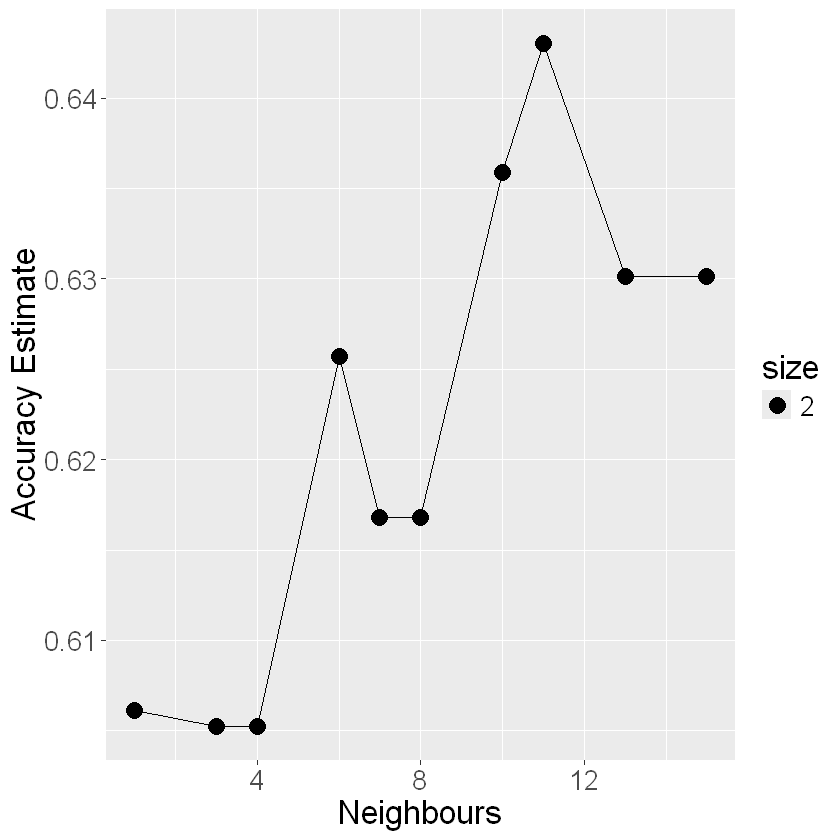

In [11]:
# plot accuracies of all values of k

ggplot(k_model_tuning_accuracies) +
    geom_line(aes(x=neighbors, y=mean)) +
    geom_point(aes(x=neighbors, y=mean, size=2)) +
    labs(x = "Neighbours", y = "Accuracy Estimate") +
    theme(text = element_text(size=20))

# Print best value of k
best_k <- k_model_tuning_accuracies %>% arrange(desc(mean)) %>% head(1) %>% pull(neighbors)
print("Best k-value:")
print(best_k)

In [13]:
# retrain model on best k-value

# Create model specification
model_spec <- nearest_neighbor(weight_func = "rectangular", neighbors = best_k ) %>%
    set_engine("kknn") %>%
    set_mode("classification")

model <- workflow() %>%
    add_recipe(recipe) %>%
    add_model(model_spec) %>%
    # fit_resamples(resamples = train_vfold) # for v-fold cross validation
    fit(data = train_data) # to train on whole train set with no validation set

model

══ Workflow [trained] ══════════════════════════════════════════════════════════
Preprocessor: Recipe
Model: nearest_neighbor()

── Preprocessor ────────────────────────────────────────────────────────────────
2 Recipe Steps

• step_scale()
• step_center()

── Model ───────────────────────────────────────────────────────────────────────

Call:
kknn::train.kknn(formula = ..y ~ ., data = data, ks = min_rows(11L,     data, 5), kernel = ~"rectangular")

Type of response variable: nominal
Minimal misclassification: 0.3758389
Best kernel: rectangular
Best k: 11

In [14]:
# Predict on the test set, and create a new DataFrame with inputs and outputs
test_predictions <- model %>% predict(test_data) %>%
    bind_cols(test_data)

In [15]:
# test_predictions

In [16]:
# What was the accuracy of our model?
test_predictions %>%
    metrics(truth = does_it_match, estimate = .pred_class)

.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
accuracy,binary,0.630769231
kap,binary,-0.005154639


In [17]:
# test_predictions %>% pull(does_it_match) %>% levels()
confusion_matrix <- test_predictions %>%
    conf_mat(truth = does_it_match, estimate = .pred_class)
confusion_matrix

          Truth
Prediction  0  1
         0 40 22
         1  2  1

In [18]:
# Test classifier on a random row in the DataFrame
test_observation <- slice_sample(test_data %>% mutate(across(where(is.numeric), ~ replace_na(.x, 0))), n=1)
print(test_observation)
test_prediction <- model %>% predict(test_observation)
print(test_prediction)

# A tibble: 1 × 18
  UST   does_it_match D_M1_M2 D_M1_M3 D_M1_M4 D_M1_M5 D_M1_M6 M2_last_UST
  <fct> <fct>           <dbl>   <dbl>   <dbl>   <dbl>   <dbl> <fct>      
1 8     1                94.0    39.7    61.2    63.0    51.2 8          
# ℹ 10 more variables: M3_last_UST <fct>, M4_last_UST <fct>, M5_last_UST <fct>,
#   M6_last_UST <fct>, time_since_M2_last_song <dbl>,
#   time_since_M3_last_song <dbl>, time_since_M4_last_song <dbl>,
#   time_since_M5_last_song <dbl>, time_since_M6_last_song <dbl>,
#   time_rel_sunrise <dbl>
# A tibble: 1 × 1
  .pred_class
  <fct>      
1 0          
